In [1]:
import sys
sys.path.append('../..')
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
import numpy as np

## Load the dataset

In [2]:
import ampligraph
# Benchmark datasets are under ampligraph.datasets module
from ampligraph.datasets import load_fb15k_237
# load fb15k-237 dataset
dataset = load_fb15k_237(return_mapper=True)

## Train the model

In [3]:
# Import the KGE model
from ampligraph.latent_features import ScoringBasedEmbeddingModel

# you can continue training from where you left after restoring the model
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir='./transe_train_logs')

# create the model with transe scoring function
model = ScoringBasedEmbeddingModel(eta=5, 
                                     k=300,
                                     scoring_type='TransE')

# you can either use optimizers/regularizers/loss/initializers with default values or you can 
# import it and customize the hyperparameters and pass it to compile

# Let's create an adam optimizer with customized learning rate =0.005
adam = tf.keras.optimizers.Adam(learning_rate=0.005)
# Let's compile the model with self_advarsarial loss of default parameters
model.compile(optimizer=adam, loss='self_adversarial')

# fit the model to data.
model.fit(dataset['train'],
             batch_size=10000,
             epochs=10,
             callbacks=[tensorboard_callback])

# the training can be visualised using the following command:
# tensorboard --logdir='./transe_train_logs' --port=8891 
# open the browser and go to the following URL: http://127.0.0.1:8891/

Epoch 1/10
29/29 [==============================] - 5s 156ms/step - loss: 37337.9141
Epoch 2/10
29/29 [==============================] - 4s 123ms/step - loss: 22925.0820
Epoch 3/10
29/29 [==============================] - 4s 141ms/step - loss: 17544.7773
Epoch 4/10
29/29 [==============================] - 3s 107ms/step - loss: 14791.7217
Epoch 5/10
29/29 [==============================] - 3s 105ms/step - loss: 13135.1875
Epoch 6/10
29/29 [==============================] - 3s 96ms/step - loss: 12037.6855
Epoch 7/10
29/29 [==============================] - 3s 104ms/step - loss: 11262.1426
Epoch 8/10
29/29 [==============================] - 3s 111ms/step - loss: 10686.5928
Epoch 9/10
29/29 [==============================] - 3s 108ms/step - loss: 10242.8730
Epoch 10/10
29/29 [==============================] - 3s 100ms/step - loss: 9892.1406


## Model calibration

In [4]:
# calibrate on the test set
model.calibrate(dataset['test'],        # Dataset to calibrate on
                batch_size=500,         # Batch size to be used for calibration
                positive_base_rate=0.8, # prior which indicates what percentage of the dataset might be correct
                epochs=1,             # Number of epochs
                verbose=True)             

100%|██████████| 1/1 [00:00<00:00,  2.60it/s]


## Save model

In [5]:
from ampligraph.utils import save_model
# explictly save the model
save_model(model, 'saved_model_transE')

The path saved_model_transE already exists. This save operation will overwrite the model                 at the specified path.
WARNING - Found untraced functions such as _get_ranks, calibration_layer_layer_call_fn, calibration_layer_layer_call_and_return_conditional_losses while saving (showing 3 of 3). These functions will not be directly callable after loading.


## Restore model

In [6]:
from ampligraph.utils import restore_model

# restore saved models or checkpoints
model = restore_model('saved_model_transE')

Saved model does not include a db file. Skipping.


## Single prediction explanation

In [7]:
from ampligraph.explanations import ExamplE

In [8]:
explainer = ExamplE(dataset, model)

In [9]:
target_triple = dataset['test'][35]

In [10]:
print(target_triple)

['/m/02ghq' '/people/person/profession' '/m/01d_h8']


In [11]:
explanation = explainer.predict_explain(target_triple)

In [12]:
import json

class NpEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer):
            return int(obj)
        if isinstance(obj, np.floating):
            return float(obj)
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return json.JSONEncoder.default(self, obj)

In [13]:
with open('explanation.json','w') as f:
    f.write(json.dumps(explanation, cls=NpEncoder))

In [14]:
with open('explanation.json') as f:
    explanation = json.loads(f.read())

In [15]:
print(explanation.keys())

dict_keys(['prediction', 'probability', 'examples', 'resembles', 'prototype', 'query_triple', 'N-hood'])


### List past examples similr to target triple

In [16]:
explanation['resembles']

[['/m/01d_h8', 'resembles', '/m/015cjr'],
 ['/m/01d_h8', 'resembles', '/m/018gz8'],
 ['/m/01d_h8', 'resembles', '/m/01d_h8'],
 ['/m/01d_h8', 'resembles', '/m/02hrh1q'],
 ['/m/01d_h8', 'resembles', '/m/02hv44_'],
 ['/m/01d_h8', 'resembles', '/m/02jknp'],
 ['/m/01d_h8', 'resembles', '/m/02krf9'],
 ['/m/01d_h8', 'resembles', '/m/03gjzk'],
 ['/m/01d_h8', 'resembles', '/m/05z96'],
 ['/m/01d_h8', 'resembles', '/m/09jwl'],
 ['/m/01d_h8', 'resembles', '/m/0cbd2'],
 ['/m/01d_h8', 'resembles', '/m/0dxtg'],
 ['/m/01d_h8', 'resembles', '/m/0kyk'],
 ['/m/01d_h8', 'resembles', '/m/0np9r'],
 ['/m/02ghq', 'resembles', '/m/014y6'],
 ['/m/02ghq', 'resembles', '/m/019z7q'],
 ['/m/02ghq', 'resembles', '/m/01_k0d'],
 ['/m/02ghq', 'resembles', '/m/01g6bk'],
 ['/m/02ghq', 'resembles', '/m/01hc9_'],
 ['/m/02ghq', 'resembles', '/m/01ksr1'],
 ['/m/02ghq', 'resembles', '/m/01yf85'],
 ['/m/02ghq', 'resembles', '/m/01zkxv'],
 ['/m/02ghq', 'resembles', '/m/022qw7'],
 ['/m/02ghq', 'resembles', '/m/02cgb8'],
 ['/m/02

In [17]:
from ampligraph.datasets import load_fb15k_237
X = load_fb15k_237(return_mapper=True)
print("\n".join([f"{x[0]} resembles {x[2]}" for x in np.vectorize(X['mapper'].get)(explanation['resembles'])]))

Film Producer resembles television presenter (aka Presenter)
Film Producer resembles Comedian
Film Producer resembles Film Producer
Film Producer resembles Actor
Film Producer resembles Playwright
Film Producer resembles Film director
Film Producer resembles Television Director
Film Producer resembles Television producer
Film Producer resembles Poet
Film Producer resembles Musician
Film Producer resembles Writer
Film Producer resembles Screenwriter
Film Producer resembles Author
Film Producer resembles Voice Actor
Dean Koontz resembles Anthony Head
Dean Koontz resembles Norman Mailer
Dean Koontz resembles Grant Morrison
Dean Koontz resembles Cory Doctorow
Dean Koontz resembles Haruki Murakami
Dean Koontz resembles Ryan Phillippe
Dean Koontz resembles Jessica Alba
Dean Koontz resembles Charles Stross
Dean Koontz resembles Patrick McGoohan
Dean Koontz resembles Martin Clunes
Dean Koontz resembles Dean Koontz
Dean Koontz resembles Robert Englund
Dean Koontz resembles Lee Grant
Dean Koontz

In [18]:
print("\n".join([f"{x[0]} {explanation['examples'][i][1]} {x[2]}" for i, x in enumerate(np.vectorize(X['mapper'].get)(explanation['examples']))]))

Anthony Head /people/person/profession Actor
Anthony Head /people/person/profession Musician
Norman Mailer /people/person/profession Film Producer
Norman Mailer /people/person/profession Actor
Norman Mailer /people/person/profession Playwright
Norman Mailer /people/person/profession Writer
Norman Mailer /people/person/profession Screenwriter
Grant Morrison /people/person/profession Author
Cory Doctorow /people/person/profession Writer
Haruki Murakami /people/person/profession Screenwriter
Ryan Phillippe /people/person/profession Actor
Jessica Alba /people/person/profession Actor
Charles Stross /people/person/profession Writer
Charles Stross /people/person/profession Author
Patrick McGoohan /people/person/profession Actor
Martin Clunes /people/person/profession television presenter (aka Presenter)
Martin Clunes /people/person/profession Comedian
Martin Clunes /people/person/profession Actor
Martin Clunes /people/person/profession Film director
Martin Clunes /people/person/profession Mus

## Explanations visualization

For visualizations to work you need to install extra packages pygraphviz, graphviz, pydot:

pip install pygraphviz graphviz pydot

Error: no "view" mailcap rules found for type "application/pdf"


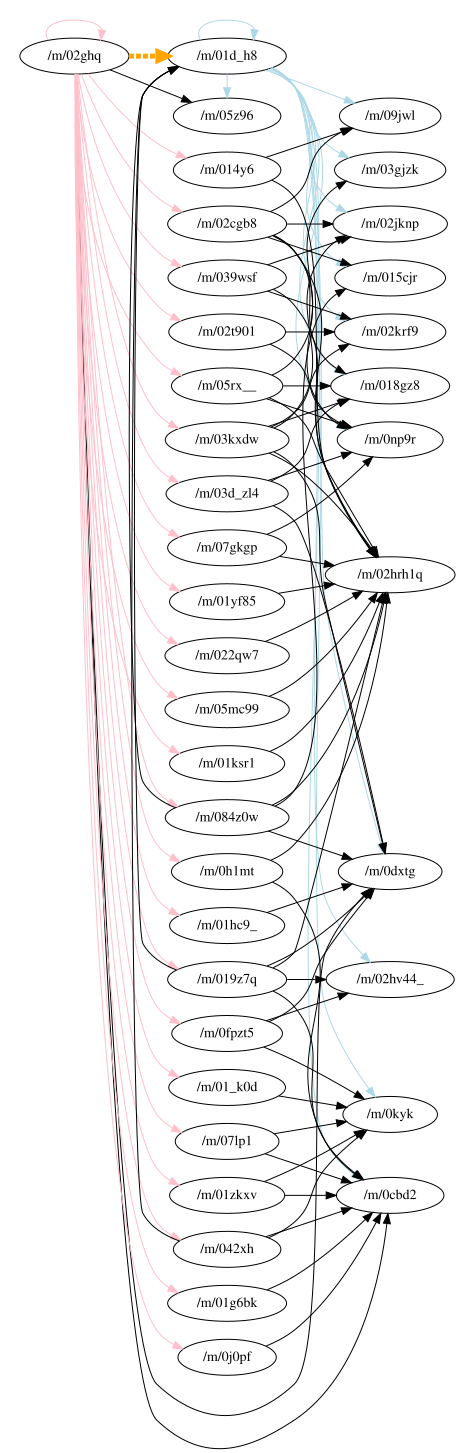

In [19]:
explainer.visualize(explanation)

In [20]:
# Translate ids into human readable labels
explanation_translated = {'prediction': explanation['prediction'], 'probability': explanation['probability'], 'query_triple': [X['mapper'].get(explanation['query_triple'][0]), explanation['query_triple'][1], X['mapper'].get(explanation['query_triple'][2])]}
for k in ['examples', 'resembles', 'prototype', 'N-hood']:
    explanation_translated[k] = [[x[0], explanation[k][i][1], x[2]] for i, x in enumerate(np.vectorize(X['mapper'].get)(explanation[k]))]

Error: no "view" mailcap rules found for type "application/pdf"


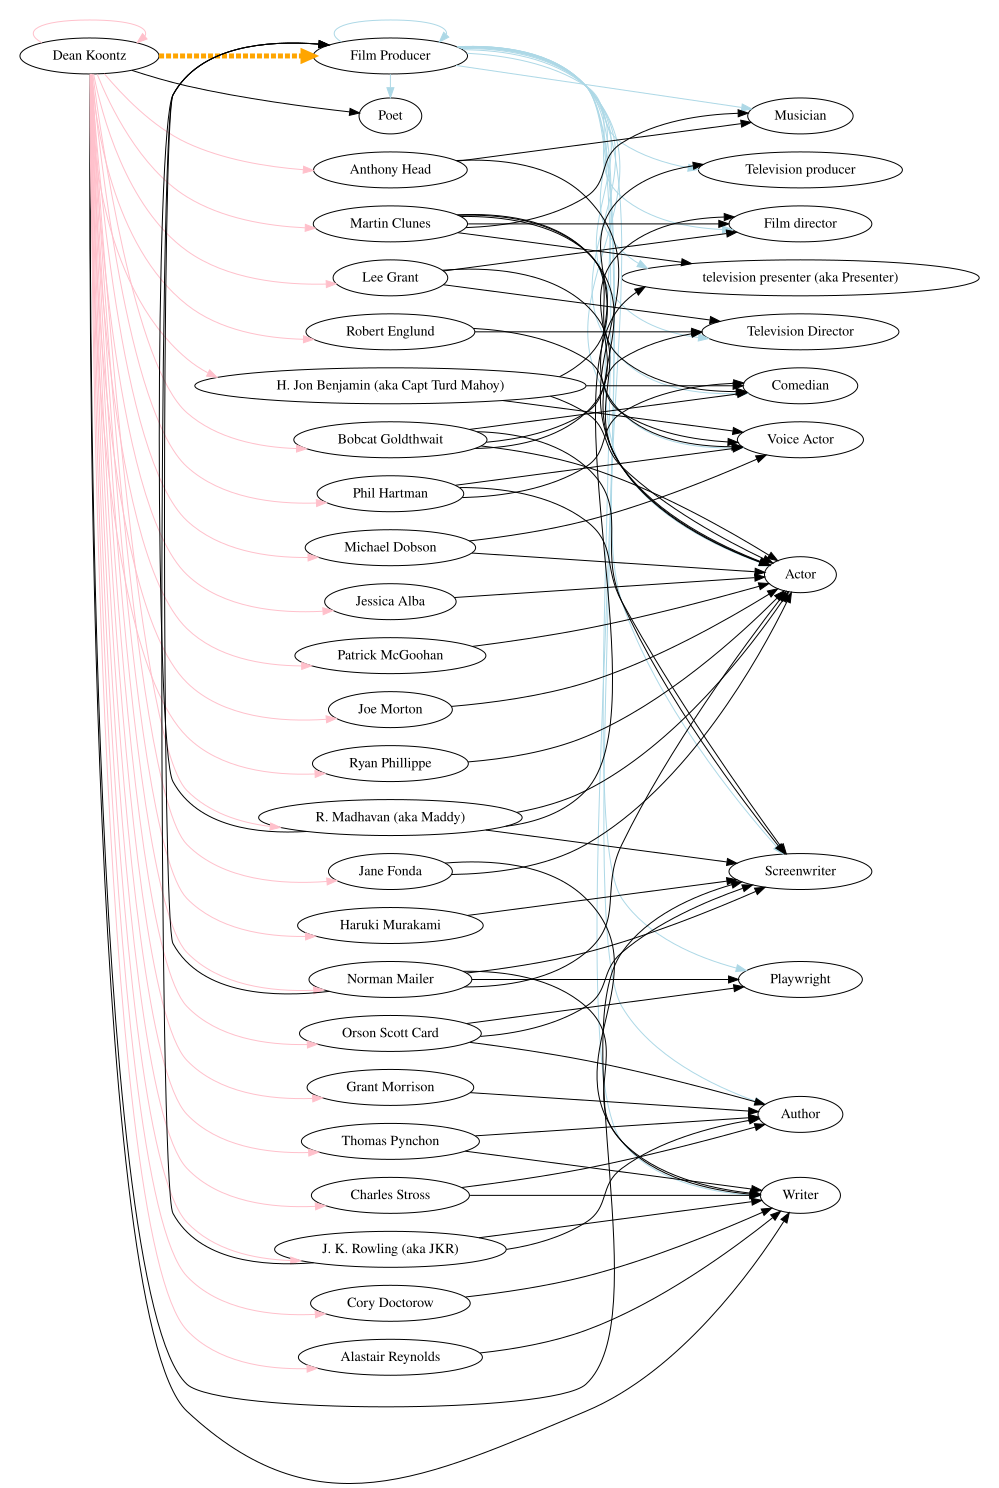

In [21]:
explainer.visualize(explanation_translated)

In [22]:
explanation.keys()

dict_keys(['prediction', 'probability', 'examples', 'resembles', 'prototype', 'query_triple', 'N-hood'])

## Batch explanations with scores

In [23]:
explanations = explainer.batch_explain([target_triple], score=True)

WARNING - Examples shape: (1, 59, 3), (1,), (1,), (1,) 


In [24]:
from ampligraph.datasets import load_fb15k_237
X = load_fb15k_237(return_mapper=True)
print("=============\n".join(["\n".join([f"{rank+1} {X['mapper'][e[0]]} {e[1]} {X['mapper'][e[2]]} distance:{float(e[3])}" for rank, e in enumerate(exp)]) for exp in explanations]))

1 Dean Koontz /people/person/profession Screenwriter distance:0.006878813107808431
2 Dean Koontz /people/person/profession Writer distance:0.010248124599456787
3 Dean Koontz /people/person/profession Poet distance:0.015095452467600504
4 Thomas Pynchon /people/person/profession Author distance:0.19443853696187338
5 Thomas Pynchon /people/person/profession Writer distance:0.19466318686803183
6 Grant Morrison /people/person/profession Author distance:0.1995335817337036
7 Patrick McGoohan /people/person/profession Actor distance:0.20147490501403809
8 Norman Mailer /people/person/profession Film Producer distance:0.2049718697865804
9 J. K. Rowling (aka JKR) /people/person/profession Film Producer distance:0.2053614060084025
10 H. Jon Benjamin (aka Capt Turd Mahoy) /people/person/profession Television producer distance:0.20606146256128946
11 H. Jon Benjamin (aka Capt Turd Mahoy) /people/person/profession Actor distance:0.20641245444615683
12 H. Jon Benjamin (aka Capt Turd Mahoy) /people/pers